# **I. Tiền xử lý chung**

**1. Kiểm tra dữ liệu gốc**

In [ ]:
# ---Nạp thư viện---
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

# ---Xác định thư mục dự án và nạp mô đun tiền xử lý---
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

project_path = str(PROJECT_ROOT.resolve())
if project_path not in sys.path:
    sys.path.insert(0, project_path)

import src.preprocessing as preprocessing

# ---Đọc bảng ứng dụng và tạo bản sao để xử lý---
apps_path = PROJECT_ROOT / "data/raw/googleplaystore.csv"
apps_raw = pd.read_csv(apps_path)
apps = apps_raw.copy()

print(f"Initial rows: {len(apps):,}")

**2. Kiểm tra và loại bản ghi lệch cột**  

Nhóm loại bản ghi có dấu hiệu lệch cột vì nhiều giá trị không phù hợp với ý nghĩa của thuộc tính và chưa có căn cứ khôi phục chính xác. Sau đó, nhóm loại các dòng trùng lặp hoàn toàn, giữ lần xuất hiện đầu tiên. Các bản ghi chỉ trùng tên ứng dụng được giữ lại để xem xét theo từng câu hỏi phân tích.

In [ ]:
# ---Hiển thị bản ghi có dấu hiệu lệch cột---
malformed_mask = preprocessing.malformed_app_mask(apps)
print("Suspected malformed rows:")
display(apps.loc[malformed_mask])

# ---Loại bản ghi lệch cột và báo cáo số dòng---
rows_before = len(apps)
apps = apps.loc[~malformed_mask].copy()

print(f"Rows before: {rows_before:,}")
print(f"Rows removed: {rows_before - len(apps):,}")
print(f"Rows after: {len(apps):,}")

Nhóm xác định và loại một bản ghi của ứng dụng Life Made WI-Fi Touchscreen Photo Frame, có nhiều giá trị không phù hợp với ý nghĩa của cột. Số dòng giảm từ 10.841 xuống 10.840.

**3. Loại bản sao hoàn toàn**  



In [ ]:
# ---Loại bản sao hoàn toàn và giữ lần xuất hiện đầu tiên---
rows_before = len(apps)
duplicate_count = apps.duplicated().sum()
apps = apps.drop_duplicates(keep="first").copy()

print(f"Rows before: {rows_before:,}")
print(f"Exact duplicates removed: {duplicate_count:,}")
print(f"Rows after: {len(apps):,}")
print(f"Remaining exact duplicates: {apps.duplicated().sum():,}")

Nhóm loại 483 bản sao giống nhau hoàn toàn, giữ lại bản ghi xuất hiện đầu tiên. Bảng còn 10.357 dòng và không còn dòng trùng lặp hoàn toàn.

**4. Kiểm tra các bản ghi trùng tên còn lại**

In [ ]:
# ---Thống kê các tên ứng dụng còn xuất hiện nhiều lần---
repeated_names = apps["App"].duplicated(keep=False)
extra_rows = apps["App"].duplicated().sum()
repeated_app_count = apps.loc[repeated_names, "App"].nunique()

name_summary = pd.Series({
    "Remaining rows": len(apps),
    "Distinct app names": apps["App"].nunique(),
    "Extra rows with repeated app names": extra_rows,
    "App names appearing more than once": repeated_app_count
})
display(name_summary)

Bảng còn 9.659 tên ứng dụng phân biệt. Trong đó, 523 tên xuất hiện nhiều lần, tạo ra 698 bản ghi thêm ngoài lần xuất hiện đầu tiên. Nhóm chưa loại các bản ghi này vì cùng tên không đồng nghĩa với thông tin hoàn toàn giống nhau; cách xử lý sẽ được xác định theo đơn vị phân tích của từng câu hỏi.

**5. Chuyển đổi các cột số**  

Nhóm sẽ thực hiện chuyển đổi các cột số như sau:  
- Giữ nguyên cột `Rating` vì đã có kiểu float64
- `Reviews` và `Installs` sang kiểu Int64
- `Price` sang float64  
- Giữ cột `Size` gốc dưới dạng `string`, thêm `Size_MB` kiểu `float64` để tính toán và `Size_varies` kiểu `boolean` để nhận diện placeholder  

Trước khi chuyển đổi, nhóm loại dấu phẩy và dấu + trong `Installs`, cùng ký hiệu $ trong `Price`. Giá trị `Installs` sau chuyển đổi vẫn là cận dưới của lượt cài đặt.

In [ ]:
rows_before = len(apps)

# ---Chuyển Rating và Reviews sang kiểu số---
rating = pd.to_numeric(apps["Rating"], errors="raise")
rating = rating.astype("float64")
reviews = pd.to_numeric(apps["Reviews"], errors="raise")
reviews = reviews.astype("Int64")

# ---Bỏ ký hiệu trong Installs và giữ ý nghĩa cận dưới---
install_text = apps["Installs"].astype("string")
install_text = install_text.str.replace(",", "", regex=False)
install_text = install_text.str.replace("+", "", regex=False)
installs = pd.to_numeric(install_text, errors="raise")
installs = installs.astype("Int64")

# ---Bỏ ký hiệu đô la và chuyển Price sang kiểu số---
price_text = apps["Price"].astype("string")
price_text = price_text.str.replace("$", "", regex=False)
price = pd.to_numeric(price_text, errors="raise")
price = price.astype("float64")

# ---Phân biệt kích thước thiếu và kích thước tùy thiết bị---
size_text = apps["Size"].astype("string").str.strip()
size_varies = (size_text == "Varies with device").fillna(False)
size_missing = size_text.isna() | (size_text == "").fillna(False)
size_parts = size_text.str.extract(r"^(\d+(?:\.\d+)?)([Mk])$")
unexpected_size = (
    ~size_missing & ~size_varies & size_parts[0].isna()
)

if unexpected_size.any():
    display(apps.loc[unexpected_size, ["App", "Size"]])
    raise ValueError("Unrecognized Size values remain.")

# ---Đổi kích thước sang MB theo quy ước k chia 1024---
size_value = pd.to_numeric(size_parts[0], errors="raise")
size_factor = size_parts[1].map({"M": 1.0, "k": 1 / 1024})
size_mb = (size_value * size_factor).astype("float64")

# ---Cập nhật bảng sau khi các phép chuyển đổi thành công---
apps["Rating"] = rating
apps["Reviews"] = reviews
apps["Installs"] = installs
apps["Price"] = price
apps["Size_MB"] = size_mb
apps["Size_varies"] = size_varies

# ---Kiểm tra kiểu dữ liệu và miền giá trị của năm cột số---
numeric_cols = ["Rating", "Reviews", "Size_MB", "Installs", "Price"]
numeric_values = apps[numeric_cols]
conversion_summary = pd.DataFrame({
    "Dtype": numeric_values.dtypes.astype(str),
    "Missing count": numeric_values.isna().sum(),
    "Negative count": (numeric_values < 0).sum(),
    "Min": numeric_values.min(),
    "Max": numeric_values.max()
})

print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(apps):,}")
display(conversion_summary)

invalid_rating = (
    apps["Rating"].notna() & ~apps["Rating"].between(1, 5)
)
nonpositive_size = (apps["Size_MB"] <= 0).sum()
print(f"Ratings outside 1-5: {invalid_rating.sum():,}")
print(f"Missing original Size: {size_missing.sum():,}")
print(f"Size varies with device: {size_varies.sum():,}")
print(f"Nonpositive Size_MB: {nonpositive_size:,}")

preview_cols = [
    "App", "Rating", "Reviews", "Size", "Size_MB",
    "Size_varies", "Installs", "Price"
]
display(apps[preview_cols].head())

**Nhận xét:**  
- Các cột số đã có kiểu dữ liệu đúng như dự kiến. `Reviews`, `Installs` và `Price` không có giá trị thiếu hoặc âm   
- `Rating` còn 1.465 giá trị thiếu; các điểm quan sát được đều nằm trong thang 1–5  
- `Size_MB` có 1.526 giá trị NaN, tương ứng hoàn toàn với các bản ghi Varies with device. Cột `Size` gốc không thiếu, cờ `Size_varies` giúp nhận diện các trường hợp kích thước chưa xác định  
- Không phát hiện kích thước nhỏ hơn hoặc bằng 0. Bước chuyển đổi không loại thêm bản ghi  

**6. Chuyển đổi cột thời gian `Last Updated`**  

Nhóm chuyển kiểu dữ liệu cột `Last Updated` từ chuỗi sang kiểu `datetime64[ns]` để hỗ trợ so sánh và trích xuất thông tin ngày tháng. Cột này biểu diễn lần cập nhật cuối của ứng dụng, không phải ngày phát hành hoặc ngày thu thập dữ liệu.

In [ ]:
rows_before = len(apps)
missing_before = apps["Last Updated"].isna().sum()

# ---Chuyển ngày theo định dạng gốc, ví dụ January 7, 2018---
last_updated = pd.to_datetime(
    apps["Last Updated"], format="%B %d, %Y", errors="raise"
)
apps["Last Updated"] = last_updated.astype("datetime64[ns]")

# ---Kiểm tra kiểu dữ liệu, giá trị thiếu và khoảng thời gian---
print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(apps):,}")
print(f"Dtype: {apps['Last Updated'].dtype}")
print(f"Missing values before: {missing_before:,}")
print(f"Missing values after: {apps['Last Updated'].isna().sum():,}")
print(f"Earliest date: {apps['Last Updated'].min():%d/%m/%Y}")
print(f"Latest date: {apps['Last Updated'].max():%d/%m/%Y}")
display(apps[["App", "Last Updated"]].head())

Cột `Last Updated` đã được chuyển sang kiểu `datetime64[ns]`, không phát sinh giá trị thiếu. Ngày cập nhật nhỏ nhất là 21/05/2010, lớn nhất là 08/08/2018. Số dòng giữ nguyên ở 10.357.

**7. Xử lý `Type` thiếu và kiểm tra với `Price`**

In [ ]:
rows_before = len(apps)

# ---Nhận diện và hiển thị các bản ghi thiếu Type---
type_text = apps["Type"].astype("string").str.strip()
missing_type = type_text.isna() | (type_text == "").fillna(False)
print("Rows with missing Type before processing:")
display(apps.loc[missing_type, ["App", "Type", "Price", "Installs"]])

# ---Suy ra Type còn thiếu từ giá hợp lệ---
infer_free = missing_type & (apps["Price"] == 0)
infer_paid = missing_type & (apps["Price"] > 0)
apps.loc[infer_free, "Type"] = "Free"
apps.loc[infer_paid, "Type"] = "Paid"

# ---Kiểm tra nhãn thiếu, nhãn lạ và mâu thuẫn với Price---
type_after = apps["Type"].astype("string").str.strip()
missing_after = (
    type_after.isna() | (type_after == "").fillna(False)
)
invalid_type = ~missing_after & ~type_after.isin(["Free", "Paid"])
conflict = (
    ((type_after == "Free") & (apps["Price"] > 0))
    | ((type_after == "Paid") & (apps["Price"] == 0))
).fillna(False)

type_summary = pd.Series({
    "Missing Type before": missing_type.sum(),
    "Inferred Free": infer_free.sum(),
    "Inferred Paid": infer_paid.sum(),
    "Missing Type after": missing_after.sum(),
    "Invalid Type labels": invalid_type.sum(),
    "Type-Price conflicts": conflict.sum()
})
display(type_summary)

print("Rows with invalid Type or Type-Price conflicts:")
display(apps.loc[invalid_type | conflict, ["App", "Type", "Price"]])
print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(apps):,}")

Bản ghi "Command & Conquer: Rivals" thiếu `Type` và có `Price` = 0, nên nhóm suy ra nhãn Free. Sau xử lý, cột `Type` không còn giá trị thiếu hoặc nhãn không hợp lệ. Nhóm cũng không phát hiện thêm bản ghi có `Type` mâu thuẫn với `Price`. Do đó số dòng được giữ nguyên.

Các giá trị thiếu của `Rating`, `Current Ver` và `Android Ver` được giữ trong bảng chung. Việc lọc theo điểm đánh giá hoặc tạo nhóm `Unknown` sẽ được thực hiện riêng khi câu hỏi cần đến.

**8. Chuyển kiểu các cột phân loại và văn bản**  

Ở phần data exploration, nhóm có một số đề xuất về việc chuyển đổi các cột biểu diễn nhãn sang kiểu `category` và các cột văn bản sang kiểu `string`. Mỗi tổ hợp trong `Genres` tiếp tục được giữ như một nhãn riêng. Cụ thể:    
- `Category`, `Type`, `Content Rating`, `Genres` → `category`
- `App`, `Size`, `Current Ver`, `Android Ver` → `string`

Giữ nguyên các nhãn tổ hợp, kể cả `Education;Education`; chưa gộp nhãn hiếm hoặc chuẩn hóa các thành phần trong bước tiền xử lý chung.

In [ ]:
rows_before = len(apps)
categorical_cols = ["Category", "Type", "Content Rating", "Genres"]
string_cols = ["App", "Size", "Current Ver", "Android Ver"]
converted_cols = categorical_cols + string_cols

# ---Ghi nhận trạng thái trước khi chuyển kiểu---
dtype_before = apps[converted_cols].dtypes.astype(str)
missing_before = apps[converted_cols].isna().sum()
distinct_before = apps[converted_cols].nunique()

# ---Chuyển các cột phân loại và văn bản---
for col in categorical_cols:
    apps[col] = apps[col].astype("category")

for col in string_cols:
    apps[col] = apps[col].astype("string")

# ---Đối chiếu kiểu dữ liệu, số giá trị thiếu và số nhãn---
conversion_summary = pd.DataFrame({
    "Dtype before": dtype_before,
    "Dtype after": apps[converted_cols].dtypes.astype(str),
    "Missing before": missing_before,
    "Missing after": apps[converted_cols].isna().sum(),
    "Distinct before": distinct_before,
    "Distinct after": apps[converted_cols].nunique()
})
display(conversion_summary)
print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(apps):,}")

**9. Kiểm tra lại cấu trúc dữ liệu của các cột**

In [ ]:
# ---Đặt lại chỉ số liên tục và xem cấu trúc bảng---
apps = apps.reset_index(drop=True)
apps.info()

Sau tiền xử lý, bảng có 10.357 dòng và 15 cột, gồm 13 cột gốc và hai cột mới `Size_MB`, `Size_varies`. Các cột số, phân loại, văn bản và ngày tháng đã có kiểu dữ liệu phù hợp với kế hoạch

# **II. Đặt câu hỏi và phân tích**

Mỗi thành viên phụ trách hai câu hỏi. Mỗi câu hỏi không dùng ML cần đáp ứng ít nhất hai tiêu chí chiều sâu; các câu hỏi của nhóm cùng bao phủ ít nhất bốn tiêu chí. Các tiêu chí gồm kết hợp dữ liệu, tái cấu trúc dữ liệu hoặc phân tích thời gian, tạo biến dẫn xuất, kiểm soát yếu tố gây nhiễu, lượng hóa độ bất định và kiểm tra độ bền của kết quả.

### **2.1. So sánh điểm đánh giá giữa ứng dụng miễn phí và trả phí**

**Người thực hiện:** Phạm Hoàng Tuấn Anh

**Câu hỏi:** Trong các nhóm ứng dụng có cùng danh mục và khoảng cài đặt, điểm đánh giá giữa ứng dụng miễn phí và trả phí khác nhau như thế nào? Kết luận có thay đổi khi nâng số lượt đánh giá tối thiểu từ 10 lên 100 không?

**Động lực:** Kết quả khám phá cho thấy hai nhóm có điểm trung bình khác nhau, nhưng cũng khác nhau về danh mục và quy mô cài đặt. Vì vậy, cần so sánh trong các nhóm tương đồng thay vì chỉ dựa vào trung bình toàn mẫu. Kết quả có thể giúp nhà phát triển tham khảo đặc điểm điểm đánh giá của hai mô hình thu phí khi cân nhắc cách cung cấp sản phẩm. Điểm đánh giá không đo đầy đủ chất lượng hoặc mức độ hài lòng; phân tích này không xác định tác động nhân quả của việc thu phí.

**Các tiêu chí chiều sâu:**

- **D3:** Tạo biến phân nhóm cận dưới lượt cài đặt.
- **D4:** So sánh trong từng tổ hợp danh mục và nhóm cài đặt, sau đó tổng hợp bằng cùng một bộ trọng số.
- **D5:** Ước lượng khoảng tin cậy 95% bằng lấy mẫu lặp theo tên ứng dụng.
- **D6:** Kiểm tra kết quả ở hai ngưỡng lượt đánh giá và khi tạm loại ứng dụng có giá từ 100 USD trở lên.

#### **1. Chuẩn bị dữ liệu và xác định phạm vi so sánh**

Nhóm sử dụng bảng `apps` đã làm sạch ở mục I và thực hiện các bước sau:

1. Chọn một bản ghi cho mỗi cặp `App`–`Category`: ưu tiên số lượt đánh giá lớn nhất, sau đó ngày cập nhật gần hơn, cuối cùng là thứ tự dòng gốc. Quy tắc này không chứng minh bản ghi được thu thập gần nhất. Việc giữ từng cặp giúp tránh mất danh mục của ứng dụng có nhiều danh mục.
2. Giữ điểm trong thang 1–5 và loại miễn phí hoặc trả phí. Từ cùng bảng này, tạo hai mẫu có ít nhất 10 và 100 lượt đánh giá. Không điền điểm thiếu.
3. Chia cận dưới lượt cài đặt thành năm khoảng: dưới 1.000; từ 1.000 đến dưới 10.000; từ 10.000 đến dưới 100.000; từ 100.000 đến dưới 1 triệu; từ 1 triệu trở lên.
4. Chỉ so sánh các tổ hợp danh mục–khoảng cài đặt có ít nhất 10 ứng dụng ở mỗi loại tại **cả hai ngưỡng đánh giá**. Ngưỡng này nhằm sàng lọc nhóm nhỏ, không bảo đảm ước lượng chính xác. Giữ cùng các tổ hợp để tránh thay đổi phạm vi nhóm khi kiểm tra độ bền.

Mỗi dòng phân tích đại diện cho một cặp ứng dụng–danh mục. Tên ứng dụng chỉ là dấu hiệu nhận diện thay thế vì dữ liệu không có mã ứng dụng; các cặp cùng tên có thể phụ thuộc nhau. Các bước chọn và loại dòng đều được báo cáo riêng.

In [ ]:
# ---Tạo hàm ghi nhận số dòng qua từng bước---
q1_audit_rows = []


def q1_record_step(label, before, after):
    q1_audit_rows.append({
        "Step": label,
        "Rows before": before,
        "Rows removed": before - after,
        "Rows after": after
    })


# ---Chọn một bản ghi đại diện cho mỗi cặp ứng dụng và danh mục---
q1_units = apps.sort_values(
    ["Reviews", "Last Updated"],
    ascending=[False, False], kind="stable"
)
q1_units = q1_units.drop_duplicates(["App", "Category"]).copy()
q1_record_step("Select app-category pairs", len(apps), len(q1_units))

valid_rating = q1_units["Rating"].between(1, 5)
valid_type = q1_units["Type"].isin(["Free", "Paid"])
q1_valid = q1_units.loc[valid_rating & valid_type].copy()
q1_record_step(
    "Keep valid ratings and types", len(q1_units), len(q1_valid)
)

# ---Chia cận dưới lượt cài đặt thành năm khoảng---
q1_brackets = [
    "<1K", "1K-<10K", "10K-<100K", "100K-<1M", ">=1M"
]
q1_valid["Install_Bracket"] = pd.cut(
    q1_valid["Installs"].astype("float64"),
    bins=[0, 1_000, 10_000, 100_000, 1_000_000, np.inf],
    labels=q1_brackets, right=False
)
if q1_valid["Install_Bracket"].isna().any():
    raise ValueError("Some install values have no bracket.")
q1_record_step(
    "Create install brackets", len(q1_valid), len(q1_valid)
)

# ---Tạo hai mẫu theo ngưỡng số lượt đánh giá---
q1_samples = {}
for threshold in [10, 100]:
    sample = q1_valid.loc[q1_valid["Reviews"] >= threshold].copy()
    q1_samples[threshold] = sample
    q1_record_step(
        f"Keep at least {threshold} reviews",
        len(q1_valid), len(sample)
    )

# ---Đếm số ứng dụng theo danh mục, khoảng cài đặt và loại---
q1_group_cols = ["Category", "Install_Bracket"]
q1_counts = {}
for threshold, sample in q1_samples.items():
    counts = sample.groupby(
        q1_group_cols + ["Type"], observed=True
    ).size()
    counts = counts.unstack("Type", fill_value=0)
    q1_counts[threshold] = counts.reindex(
        columns=["Free", "Paid"], fill_value=0
    )

# ---Chọn tổ hợp có ít nhất mười ứng dụng mỗi loại ở cả hai mẫu---
q1_min_per_type = 10
q1_coverage = q1_counts[10].add_suffix("_10").join(
    q1_counts[100].add_suffix("_100"), how="left"
)
q1_coverage = q1_coverage.fillna(0).astype(int)
q1_coverage["Eligible"] = (
    q1_coverage >= q1_min_per_type
).all(axis=1)
q1_common_groups = q1_coverage.index[q1_coverage["Eligible"]]
if len(q1_common_groups) == 0:
    raise ValueError("No groups are eligible at both thresholds.")

q1_analysis = {}
for threshold, sample in q1_samples.items():
    keys = pd.MultiIndex.from_frame(sample[q1_group_cols])
    selected = sample.loc[keys.isin(q1_common_groups)].copy()
    q1_analysis[threshold] = selected
    q1_record_step(
        f"Keep common groups at threshold {threshold}",
        len(sample), len(selected)
    )

# ---Giữ cùng bộ trọng số lấy từ mẫu có ít nhất mười đánh giá---
q1_reference_counts = q1_analysis[10].groupby(
    q1_group_cols, observed=True
).size()
q1_reference_counts = q1_reference_counts.reindex(q1_common_groups)
q1_weights = q1_reference_counts / q1_reference_counts.sum()

# ---Hiển thị số dòng và mức bao phủ của hai mẫu---
q1_audit = pd.DataFrame(q1_audit_rows)
display(q1_audit)
print(f"Observed groups at threshold 10: {len(q1_coverage):,}")
print(f"Common eligible groups: {len(q1_common_groups):,}")
display(q1_coverage)

q1_sample_rows = []
for threshold in [10, 100]:
    before = q1_samples[threshold]
    after = q1_analysis[threshold]
    q1_sample_rows.append({
        "Review threshold": threshold,
        "Pairs before group selection": len(before),
        "Pairs compared": len(after),
        "Retained percent": len(after) / len(before) * 100,
        "Distinct app names": after["App"].nunique(),
        "Free": (after["Type"] == "Free").sum(),
        "Paid": (after["Type"] == "Paid").sum()
    })
q1_sample_summary = pd.DataFrame(q1_sample_rows)
display(q1_sample_summary.round(2))

**Nhận xét phạm vi dữ liệu:**

- Từ 10.357 dòng, nhóm chọn được 9.744 cặp ứng dụng–danh mục; sau khi chọn điểm và loại ứng dụng hợp lệ còn 8.280 cặp. Hai ngưỡng 10 và 100 lượt đánh giá lần lượt giữ lại 7.693 và 6.383 cặp trước khi xét nhóm đối chiếu.
- Trong 157 tổ hợp danh mục–nhóm cài đặt quan sát ở ngưỡng 10, chỉ có **8 tổ hợp thuộc 5 danh mục** đủ điều kiện tại cả hai ngưỡng.
- Mẫu so sánh chính ở ngưỡng 10 có **1.462 cặp**, gồm 1.262 miễn phí và 200 trả phí, bằng **19,00%** số cặp đạt ngưỡng. Ở ngưỡng 100, mẫu có **1.137 cặp**, gồm 957 miễn phí và 180 trả phí, bằng **17,81%** số cặp đạt ngưỡng.
- Trong từng mẫu cuối, mỗi tên ứng dụng chỉ xuất hiện một lần. Quy trình lấy mẫu theo tên vẫn được giữ để xử lý nhất quán nếu phạm vi nhóm thay đổi.
- Phạm vi đối chiếu khá hẹp. Kết quả chỉ mô tả những tổ hợp đủ điều kiện, không đại diện cho toàn bộ các ứng dụng có điểm đánh giá. Nâng ngưỡng làm thay đổi thành phần ứng dụng ngay cả khi giữ nguyên danh sách tổ hợp.

#### **2. Ước lượng chênh lệch và độ bất định**

Trong mỗi tổ hợp danh mục–nhóm cài đặt, nhóm tính điểm trung bình của ứng dụng trả phí trừ điểm trung bình của ứng dụng miễn phí. Chênh lệch sau phân nhóm là trung bình có trọng số của các hiệu số này. Trọng số lấy từ số cặp ứng dụng–danh mục ở ngưỡng 10 và giữ cố định cho cả hai ngưỡng, để hai loại ứng dụng được so sánh theo cùng cơ cấu nhóm.

Bảng kết quả còn trình bày chênh lệch toàn mẫu và chênh lệch chưa phân nhóm trên cùng phạm vi đối chiếu. Các số này phục vụ mô tả, không thay thế kết quả đã phân nhóm.

Khoảng tin cậy 95% được tính bằng 1.000 lần lấy mẫu có hoàn lại theo **tên ứng dụng**. Mọi dòng cùng tên nhận cùng số lần xuất hiện trong mỗi lần lấy mẫu. Cùng một lần lấy mẫu được dùng cho hai ngưỡng để ước lượng thêm độ thay đổi của chênh lệch. Các tổ hợp và trọng số được giữ cố định, nên khoảng tin cậy có điều kiện theo phạm vi đã chọn. Không sử dụng kiểm định hai mẫu độc lập cho các dòng có thể thuộc cùng một ứng dụng.

In [ ]:
# ---Tính trung bình từng loại trong mỗi tổ hợp---
def q1_group_means(frame, app_counts=None):
    data = frame[q1_group_cols + ["Type", "Rating"]].copy()
    data["Count"] = 1.0
    if app_counts is not None:
        data["Count"] = frame["App"].map(app_counts)
    data["Rating_sum"] = data["Rating"] * data["Count"]

    totals = data.groupby(
        q1_group_cols + ["Type"], observed=True
    )[["Count", "Rating_sum"]].sum()
    counts = totals["Count"].unstack("Type", fill_value=0)
    sums = totals["Rating_sum"].unstack("Type", fill_value=0)
    counts = counts.reindex(
        index=q1_common_groups,
        columns=["Free", "Paid"], fill_value=0
    )
    sums = sums.reindex(
        index=q1_common_groups,
        columns=["Free", "Paid"], fill_value=0
    )
    means = sums / counts.replace(0, np.nan)
    return means, counts


# ---Tính chênh lệch có trọng số và chênh lệch chưa phân nhóm---
def q1_adjusted_difference(frame):
    means, counts = q1_group_means(frame)
    if (counts == 0).any().any():
        return np.nan
    differences = means["Paid"] - means["Free"]
    return (q1_weights * differences).sum()


def q1_raw_difference(frame):
    means = frame.groupby("Type", observed=True)["Rating"].mean()
    return means.get("Paid", np.nan) - means.get("Free", np.nan)


# ---Lấy mẫu theo tên để các dòng cùng ứng dụng đi cùng nhau---
q1_app_names = q1_analysis[10]["App"].drop_duplicates().to_numpy()
q1_n_apps = len(q1_app_names)
q1_rng = np.random.default_rng(42)
q1_boot_draws = []
q1_attempts = 0

while len(q1_boot_draws) < 1_000 and q1_attempts < 5_000:
    q1_attempts += 1
    sampled_indices = q1_rng.integers(q1_n_apps, size=q1_n_apps)
    sampled_names = q1_app_names[sampled_indices]
    app_counts = pd.Series(sampled_names).value_counts()
    app_counts = app_counts.reindex(q1_app_names, fill_value=0)

    differences = []
    for threshold in [10, 100]:
        means, counts = q1_group_means(
            q1_analysis[threshold], app_counts
        )
        if (counts == 0).any().any():
            differences.append(np.nan)
        else:
            group_difference = means["Paid"] - means["Free"]
            difference = (q1_weights * group_difference).sum()
            differences.append(difference)

    if np.isfinite(differences).all():
        q1_boot_draws.append(differences)

if len(q1_boot_draws) < 1_000:
    raise ValueError("Too few valid bootstrap samples.")
q1_boot_draws = np.array(q1_boot_draws)

# ---Tổng hợp ước lượng và khoảng tin cậy ở từng ngưỡng---
q1_stats_rows = []
for position, threshold in enumerate([10, 100]):
    frame = q1_analysis[threshold]
    means, counts = q1_group_means(frame)
    low, high = np.percentile(
        q1_boot_draws[:, position], [2.5, 97.5]
    )
    q1_stats_rows.append({
        "Review threshold": threshold,
        "Full sample gap": q1_raw_difference(q1_samples[threshold]),
        "Common sample gap": q1_raw_difference(frame),
        "Weighted Free rating": (q1_weights * means["Free"]).sum(),
        "Weighted Paid rating": (q1_weights * means["Paid"]).sum(),
        "Adjusted gap": q1_adjusted_difference(frame),
        "CI lower": low,
        "CI upper": high
    })
q1_statistics = pd.DataFrame(q1_stats_rows)
display(q1_statistics.round(4))

# ---Dùng cùng lần lấy mẫu để tính thay đổi giữa hai ngưỡng---
q1_change = (
    q1_statistics.loc[1, "Adjusted gap"]
    - q1_statistics.loc[0, "Adjusted gap"]
)
q1_boot_changes = q1_boot_draws[:, 1] - q1_boot_draws[:, 0]
q1_change_ci = np.percentile(q1_boot_changes, [2.5, 97.5])
low, high = q1_change_ci
invalid_draws = q1_attempts - len(q1_boot_draws)
print(f"Gap change from threshold 10 to 100: {q1_change:+.4f}")
print(f"95% CI for the change: [{low:.4f}; {high:.4f}]")
print(f"Valid bootstrap samples: {len(q1_boot_draws):,}")
print(f"Samples with missing groups: {invalid_draws:,}")

**Nhận xét thống kê:**

- Với ít nhất 10 lượt đánh giá, điểm trung bình theo cơ cấu chung là **4,087** ở nhóm miễn phí và **4,364** ở nhóm trả phí. Chênh lệch sau phân nhóm là **+0,277 điểm**, với khoảng tin cậy 95% **[0,228; 0,329]**.
- Với ít nhất 100 lượt đánh giá, chênh lệch tương ứng là **+0,275 điểm**, với khoảng tin cậy 95% **[0,214; 0,340]**. Cả hai khoảng đều nằm trên 0 theo phương pháp lấy mẫu đã chọn.
- Cần phân biệt thay đổi phạm vi và thay đổi cách tổng hợp. Ở ngưỡng 10, chênh lệch toàn mẫu là +0,096 điểm, còn chênh lệch chưa phân nhóm trên phạm vi chung là +0,271 điểm. So với +0,277 điểm sau phân nhóm, sự khác biệt lớn với toàn mẫu chủ yếu gắn với phạm vi đối chiếu khác nhau; không được quy toàn bộ thay đổi cho việc kiểm soát danh mục và mức cài đặt.

#### **3. Trực quan hóa kết quả sau phân nhóm**

Biểu đồ thứ nhất trình bày chênh lệch tổng hợp đã phân nhóm và khoảng tin cậy ở hai ngưỡng lượt đánh giá. Biểu đồ thứ hai trình bày chênh lệch theo từng danh mục thuộc phạm vi chung; trong mỗi danh mục, trọng số các nhóm cài đặt cũng được giữ cố định giữa hai ngưỡng. Biểu đồ theo danh mục chỉ mô tả các ước lượng điểm, không thể hiện ý nghĩa thống kê của từng danh mục.

In [ ]:
# ---Vẽ chênh lệch tổng hợp cùng khoảng tin cậy---
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(q1_statistics))
ax.hlines(
    positions, q1_statistics["CI lower"],
    q1_statistics["CI upper"], color="#2166ac", linewidth=2
)
ax.scatter(
    q1_statistics["Adjusted gap"], positions,
    color="#2166ac", zorder=3
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(positions)
ax.set_yticklabels(["At least 10 reviews", "At least 100 reviews"])
ax.set_xlabel("Paid minus Free rating (1-5 scale)")
ax.set_title("Adjusted rating gaps with 95% bootstrap CIs")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# ---Tổng hợp chênh lệch theo danh mục với cùng cơ cấu cài đặt---
q1_group_differences = pd.DataFrame(index=q1_common_groups)
for threshold in [10, 100]:
    means, counts = q1_group_means(q1_analysis[threshold])
    q1_group_differences[f"Threshold {threshold}"] = (
        means["Paid"] - means["Free"]
    )
q1_group_differences["Weight"] = q1_weights

q1_category_rows = []
for category, frame in q1_group_differences.groupby(
    level="Category", observed=True
):
    weights = frame["Weight"] / frame["Weight"].sum()
    q1_category_rows.append({
        "Category": category,
        "Threshold 10": (weights * frame["Threshold 10"]).sum(),
        "Threshold 100": (weights * frame["Threshold 100"]).sum(),
        "Groups": len(frame)
    })
q1_category_results = pd.DataFrame(q1_category_rows)
q1_category_results = q1_category_results.sort_values("Threshold 10")
display(q1_category_results.round(4))

# ---Vẽ chênh lệch theo danh mục ở hai ngưỡng đánh giá---
height = max(4.5, len(q1_category_results) * 0.5)
fig, ax = plt.subplots(figsize=(10, height))
positions = np.arange(len(q1_category_results))
plot_settings = [(-0.16, 10, "#2166ac"), (0.16, 100, "#b2182b")]
for offset, threshold, color in plot_settings:
    ax.barh(
        positions + offset,
        q1_category_results[f"Threshold {threshold}"],
        height=0.3, color=color,
        label=f"At least {threshold} reviews"
    )
ax.set_yticks(positions)
ax.set_yticklabels(q1_category_results["Category"])
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Paid minus Free rating (1-5 scale)")
ax.set_title("Rating gaps by category after install adjustment")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét biểu đồ:**

- Biểu đồ thứ nhất cho thấy hai ước lượng chênh lệch tổng hợp gần nhau; cả hai khoảng tin cậy đều nằm phía trên đường mốc 0. Độ thay đổi giữa hai ngưỡng được đánh giá riêng ở phần kiểm tra độ bền, không suy ra chỉ từ việc hai khoảng tin cậy chồng lấn.
- Trong năm danh mục được giữ lại, các ước lượng điểm đều dương ở cả hai ngưỡng. Tuy nhiên, mức chênh lệch khác nhau giữa danh mục: `TOOLS` có hiệu số lớn hơn các danh mục còn lại, còn `PERSONALIZATION` có hiệu số nhỏ hơn.
- Mỗi danh mục chỉ được đại diện bởi các khoảng cài đặt đủ điều kiện, không phải toàn bộ ứng dụng trong danh mục. Biểu đồ thứ hai không có khoảng tin cậy riêng cho danh mục nên không dùng để kết luận ý nghĩa thống kê hoặc xếp hạng chắc chắn giữa các danh mục.

#### **4. Kiểm tra độ bền của kết quả**

Nhóm đối chiếu kết quả ở ngưỡng 10 và 100 lượt đánh giá trên cùng các tổ hợp và cùng trọng số. Ngoài ra, nhóm tính lại chênh lệch sau khi tạm loại bản ghi có giá từ 100 USD trở lên. Số bản ghi bị loại được tính riêng trong từng mẫu, không sử dụng số 20 của bảng gốc.

Ngưỡng giá cao là lựa chọn kiểm tra độ nhạy, không có nghĩa các bản ghi này là sai hoặc không có chất lượng. Nếu sau khi lọc có tổ hợp thiếu một loại ứng dụng, chênh lệch sẽ không được tính thay vì thay giá trị thiếu bằng 0.

In [ ]:
# ---Tạm loại giá cao và tính lại chênh lệch với cùng trọng số---
q1_price_rows = []
for threshold in [10, 100]:
    before = q1_analysis[threshold]
    after = before.loc[before["Price"] < 100].copy()
    means, counts = q1_group_means(after)
    small_groups = (counts < 10).any(axis=1).sum()
    missing_groups = (counts == 0).any(axis=1).sum()
    q1_price_rows.append({
        "Review threshold": threshold,
        "Rows before": len(before),
        "High-price rows removed": len(before) - len(after),
        "Rows after": len(after),
        "Original gap": q1_adjusted_difference(before),
        "Gap without high prices": q1_adjusted_difference(after),
        "Groups below 10 in either type": small_groups,
        "Groups missing a type": missing_groups
    })
q1_price_sensitivity = pd.DataFrame(q1_price_rows)
q1_price_sensitivity["Gap change"] = (
    q1_price_sensitivity["Gap without high prices"]
    - q1_price_sensitivity["Original gap"]
)
display(q1_price_sensitivity.round(4))

**Nhận xét kiểm tra độ bền:**

- Khi nâng ngưỡng từ 10 lên 100 lượt đánh giá, chênh lệch sau phân nhóm thay đổi từ **+0,277** xuống **+0,275 điểm**. Độ thay đổi là **-0,002 điểm**, với khoảng tin cậy 95% **[-0,043; 0,043]** chứa 0. Trong phạm vi và phương pháp hiện tại, chưa có bằng chứng rõ về sự thay đổi của hiệu số khi nâng ngưỡng.
- Khi tạm loại giá từ 100 USD trở lên, **mỗi mẫu loại 3 bản ghi**, không phải 20 bản ghi của bảng gốc. Chênh lệch sau phân nhóm lần lượt là **+0,281** và **+0,280 điểm**, tăng khoảng **0,0042** và **0,0046 điểm** so với ban đầu. Không có tổ hợp nào giảm xuống dưới 10 ứng dụng ở một loại.
- Chiều chênh lệch không đảo trong hai lựa chọn đã kiểm tra. Điều này hỗ trợ tính ổn định của kết quả trong mẫu đối chiếu, không chứng minh một quy luật chung hoặc việc ứng dụng trả phí có chất lượng tốt hơn.

#### **5. Trả lời câu hỏi và giới hạn**

**Trả lời câu hỏi:** Trong 8 tổ hợp danh mục–khoảng cài đặt đủ điều kiện, nhóm trả phí có điểm trung bình cao hơn nhóm miễn phí khoảng **0,277 điểm** ở ngưỡng 10 lượt đánh giá và **0,275 điểm** ở ngưỡng 100. Đây là các chênh lệch được tổng hợp bằng cùng cơ cấu nhóm. Hai khoảng tin cậy 95% đều nằm trên 0.

**Độ bền:** Nâng ngưỡng không đảo chiều kết quả và chỉ làm hiệu số thay đổi khoảng -0,002 điểm; khoảng tin cậy của thay đổi chứa 0. Tạm loại giá cao cũng không đảo chiều kết quả. Các kết luận về thay đổi giữa hai ngưỡng dựa trên hiệu số sau phân nhóm, không dựa vào mức tăng của chênh lệch toàn mẫu.

**Ý nghĩa thực tiễn:** Kết quả cho thấy mối liên hệ giữa mô hình thu phí và điểm đánh giá trong phạm vi đối chiếu. Đây là một thông tin tham khảo cho nhà phát triển, chưa đủ để khuyến nghị chuyển sang thu phí hoặc khẳng định mua ứng dụng trả phí sẽ đem lại trải nghiệm tốt hơn.

**Giới hạn:**


- Kết quả chỉ áp dụng cho các tổ hợp có đủ ứng dụng miễn phí và trả phí ở cả hai ngưỡng. Các ứng dụng thiếu điểm hoặc không có nhóm đối chiếu không nằm trong phạm vi kết luận.
- Khoảng cài đặt dựa trên cận dưới, không phải lượt cài chính xác. Phân nhóm không loại hết khác biệt về mức độ phổ biến và các yếu tố chưa quan sát.
- Một tên có thể không phải một mã ứng dụng duy nhất. Quy tắc chọn bản ghi đại diện và lấy mẫu theo tên chỉ là cách xử lý theo thông tin sẵn có.
- Trên bảng trước khi chọn tổ hợp, ứng dụng có nhiều danh mục có thể đóng góp nhiều cặp. Trong mẫu đối chiếu hiện tại mỗi tên chỉ còn một cặp; trọng số tổng hợp vẫn được xác định theo tổ hợp, không phải điểm trung bình toàn mẫu thông thường.
- Khoảng tin cậy mô tả độ bất định trong mẫu và phạm vi đã chọn; không khắc phục sai lệch thu thập hoặc khiến dataset đại diện cho toàn bộ Google Play.
- Dữ liệu không đo quảng cáo, giao dịch mua trong ứng dụng hoặc chất lượng trải nghiệm. Không suy ra nguyên nhân của điểm số, đánh giá ảo hay hiệu quả của việc chuyển mô hình thu phí.

### **2.2. Độ mới của bản cập nhật và mức phổ biến của ứng dụng**

**Người thực hiện:** *(điền tên thành viên)*

**Câu hỏi:** Ứng dụng được cập nhật gần đây có tỷ lệ đạt từ 1.000.000 lượt cài trở lên cao hơn ứng dụng lâu không cập nhật hay không? Mối liên hệ này còn giữ khi so sánh trong cùng danh mục và cùng loại miễn phí hoặc trả phí không?

**Động lực:** Khám phá cho thấy ứng dụng khác nhau rất nhiều về `Installs`, `Price` và danh mục, trong khi `Last Updated` chưa được khai thác. Kết quả giúp nhà phát triển và nhà phát hành cân nhắc việc duy trì cập nhật. Đây là mối liên hệ quan sát: ứng dụng phổ biến có thể được cập nhật thường xuyên hơn, chứ chưa chắc cập nhật làm tăng lượt cài.

**Các tiêu chí chiều sâu:**

- **D2:** Tính thời gian từ lần cập nhật cuối đến ngày tham chiếu, so sánh theo nhóm thời gian và theo tháng cập nhật.
- **D3:** Tạo `Days_since_update`, nhóm thời gian, nhóm kích thước và nhãn phổ biến.
- **D4:** So sánh trong từng tầng danh mục × loại (Free hoặc Paid), rồi tổng hợp bằng trọng số cỡ tầng và kiểm tra riêng từng danh mục.
- **D5:** Khoảng tin cậy bootstrap 95% (lấy mẫu lại ứng dụng) và hệ số Spearman kèm p-value.
- **D6:** Đổi ngưỡng "mới", cách phân tầng, phạm vi mẫu và ngưỡng phổ biến.

#### **1. Chuẩn bị dữ liệu và tạo biến (D2, D3)**

1. Từ bảng `apps` đã làm sạch, nhóm giữ một dòng cho mỗi tên ứng dụng (ưu tiên `Reviews` lớn nhất, rồi `Last Updated` mới hơn) để mỗi ứng dụng chỉ được tính một lần.
2. Ngày tham chiếu là `Last Updated` muộn nhất trong dữ liệu (xấp xỉ ngày thu thập). `Days_since_update` là số ngày từ lần cập nhật cuối đến ngày này.
3. `Age_group` chia thành 5 nhóm; `Popular` bằng 1 nếu cận dưới `Installs` từ 1.000.000; `Size_group` chia kích thước thành 4 nhóm (gồm "Varies").

In [14]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# ---------- 1. Một bản ghi cho mỗi tên ứng dụng ----------
q2_rows_before = len(apps)
q2 = (
    apps.sort_values(["Reviews", "Last Updated"], ascending=False, kind="stable")
    .drop_duplicates("App")
    .copy()
)

# ---------- 2. Biến thời gian và biến dẫn xuất ----------
# Ngày cập nhật muộn nhất trong dữ liệu được coi là ngày thu thập.
REF_DATE = q2["Last Updated"].max()
q2["Days_since_update"] = (REF_DATE - q2["Last Updated"]).dt.days
AGE_LABELS = ["≤30 ngày", "31–90 ngày", "91–180 ngày", "181–365 ngày", ">365 ngày"]
q2["Age_group"] = pd.cut(q2["Days_since_update"], [-1, 30, 90, 180, 365, np.inf], labels=AGE_LABELS)
q2["Popular"] = q2["Installs"].ge(1_000_000)
q2["Size_group"] = pd.cut(q2["Size_MB"], [0, 5, 20, np.inf], labels=["<5MB", "5–20MB", ">20MB"]).cat.add_categories("Varies").fillna("Varies").astype(str)
q2["Category"] = q2["Category"].astype(str)
q2["Type"] = q2["Type"].astype(str)

display(pd.Series({
    "Số dòng trước": q2_rows_before,
    "Số ứng dụng (một dòng mỗi tên)": len(q2),
    "Ngày tham chiếu": REF_DATE.date(),
    "Số ngày cập nhật: trung vị": int(q2["Days_since_update"].median()),
}, name="Giá trị"))

q2_age = q2.groupby("Age_group", observed=True).agg(
    Apps=("App", "size"),
    Popular_share=("Popular", "mean"),
    Paid_share=("Type", lambda s: s.eq("Paid").mean()),
    Median_size_MB=("Size_MB", "median"),
)
display(q2_age.round(3))

Số dòng trước                          10357
Số ứng dụng (một dòng mỗi tên)          9659
Ngày tham chiếu                   2018-08-08
Số ngày cập nhật: trung vị                96
Name: Giá trị, dtype: object

,Apps,Popular_share,Paid_share,Median_size_MB
Age_group,,,,
≤30 ngày,2936,0.567,0.037,19.0
31–90 ngày,1829,0.389,0.067,14.0
91–180 ngày,1158,0.235,0.066,12.0
181–365 ngày,1320,0.229,0.074,9.5
>365 ngày,2416,0.185,0.144,6.4


Từ 10.357 dòng, nhóm còn **9.659** ứng dụng. Ngày tham chiếu là 08/08/2018 và trung vị là 96 ngày kể từ lần cập nhật cuối. Tỷ lệ phổ biến giảm theo thời gian: **56,7%** ở nhóm ≤30 ngày xuống **18,5%** ở nhóm >365 ngày. Nhóm cũ có nhiều ứng dụng trả phí hơn (14,4% so với 3,7%) và kích thước nhỏ hơn (trung vị 6,4MB so với 19MB), nên cần kiểm soát các yếu tố này.

#### **2. Ước lượng chênh lệch và độ bất định (D4, D5)**

Nhóm gọi ứng dụng cập nhật trong 90 ngày gần nhất là "mới", còn lại là "cũ". Trong mỗi tầng danh mục × loại, nhóm tính chênh lệch tỷ lệ phổ biến (mới trừ cũ), chỉ giữ tầng có ít nhất 10 ứng dụng ở cả hai nhóm, rồi lấy trung bình với trọng số bằng cỡ tầng. Khoảng tin cậy 95% lấy bằng bootstrap 1.000 lần. Nhóm cũng tính Spearman giữa `Days_since_update` và `Installs`. Ô code có một phép kiểm tra nhỏ (`assert`) cho hàm tính chênh lệch có trọng số.

In [15]:
def q2_adj_diff(codes, recent, pop, min_n=10):
    """Chênh lệch tỷ lệ phổ biến (mới − cũ) trung bình theo tầng, trọng số bằng cỡ tầng.
    Chỉ dùng tầng có ít nhất min_n ứng dụng ở cả hai nhóm."""
    k = codes.max() + 1
    n1 = np.bincount(codes[recent], minlength=k)
    n0 = np.bincount(codes[~recent], minlength=k)
    s1 = np.bincount(codes[recent], weights=pop[recent], minlength=k)
    s0 = np.bincount(codes[~recent], weights=pop[~recent], minlength=k)
    ok = (n1 >= min_n) & (n0 >= min_n)
    w = (n1 + n0)[ok]
    return np.sum(w * (s1[ok] / n1[ok] - s0[ok] / n0[ok])) / w.sum(), int(w.sum()), int(ok.sum())

# Kiểm tra nhanh: tầng A chênh 0,6 (20 app), tầng B chênh 0 (20 app), tầng C bị loại vì nhóm quá nhỏ.
_codes = np.array([0]*20 + [1]*20 + [2]*3)
_recent = np.array([True]*10 + [False]*10 + [True]*10 + [False]*10 + [True]*3)
_pop = np.array([1]*8 + [0]*2 + [1]*2 + [0]*8 + [1]*5 + [0]*5 + [1]*5 + [0]*5 + [1]*3, dtype=float)
_est, _n, _k = q2_adj_diff(_codes, _recent, _pop)
assert abs(_est - 0.3) < 1e-9 and _n == 40 and _k == 2

def q2_estimate(d, cutoff=90, strata=("Category", "Type"), thr=1_000_000, n_boot=1000, seed=42):
    """Ước lượng chênh lệch thô và sau phân tầng kèm CI bootstrap 95% (lấy mẫu lại ứng dụng)."""
    codes = d.groupby(list(strata)).ngroup().to_numpy()
    recent = d["Days_since_update"].le(cutoff).to_numpy()
    pop = d["Installs"].ge(thr).to_numpy(float)
    raw = lambda i: pop[i][recent[i]].mean() - pop[i][~recent[i]].mean()
    adj = lambda i: q2_adj_diff(codes[i], recent[i], pop[i])[0]
    all_i = np.arange(len(d))
    rng = np.random.default_rng(seed)
    boots = [rng.integers(0, len(d), len(d)) for _ in range(n_boot)]
    a, n_used, n_strata = q2_adj_diff(codes, recent, pop)
    return {"n": len(d), "Mới (n)": int(recent.sum()), "Cũ (n)": int((~recent).sum()),
            "Share mới": pop[recent].mean(), "Share cũ": pop[~recent].mean(),
            "Chênh thô": raw(all_i), "CI thô": tuple(np.percentile([raw(i) for i in boots], [2.5, 97.5])),
            "Chênh sau phân tầng": a, "CI phân tầng": tuple(np.percentile([adj(i) for i in boots], [2.5, 97.5])),
            "App dùng": n_used, "Số tầng": n_strata}

q2_main = q2_estimate(q2)
display(pd.Series(q2_main, name="Giá trị (mới = cập nhật ≤90 ngày)").to_frame())

rho, p = spearmanr(q2["Days_since_update"], q2["Installs"])
print(f"Spearman(Days_since_update, Installs) = {rho:.3f}, p = {p:.2g}")

,Giá trị (mới = cập nhật ≤90 ngày)
n,9659
Mới (n),4765
Cũ (n),4894
Share mới,0.499056
Share cũ,0.208418
Chênh thô,0.290637
CI thô,"(0.272689, 0.308318)"
Chênh sau phân tầng,0.281344
CI phân tầng,"(0.262309, 0.297476)"
App dùng,9412


Spearman(Days_since_update, Installs) = -0.332, p = 2.9e-247


- Tỷ lệ phổ biến là **49,9%** ở nhóm mới và **20,8%** ở nhóm cũ. Chênh lệch thô là **+0,291** (CI [0,273; 0,308]).
- Sau khi phân tầng danh mục × loại (38 tầng, 9.412 ứng dụng được dùng), chênh lệch còn **+0,281** (CI [0,262; 0,297]). Phân tầng gần như không làm mất mối liên hệ.
- Spearman giữa `Days_since_update` và `Installs` là **−0,332** (p < 0,001): cập nhật càng lâu thì `Installs` càng thấp, ở mức vừa phải.

#### **3. Trực quan hóa theo thời gian (D2)**

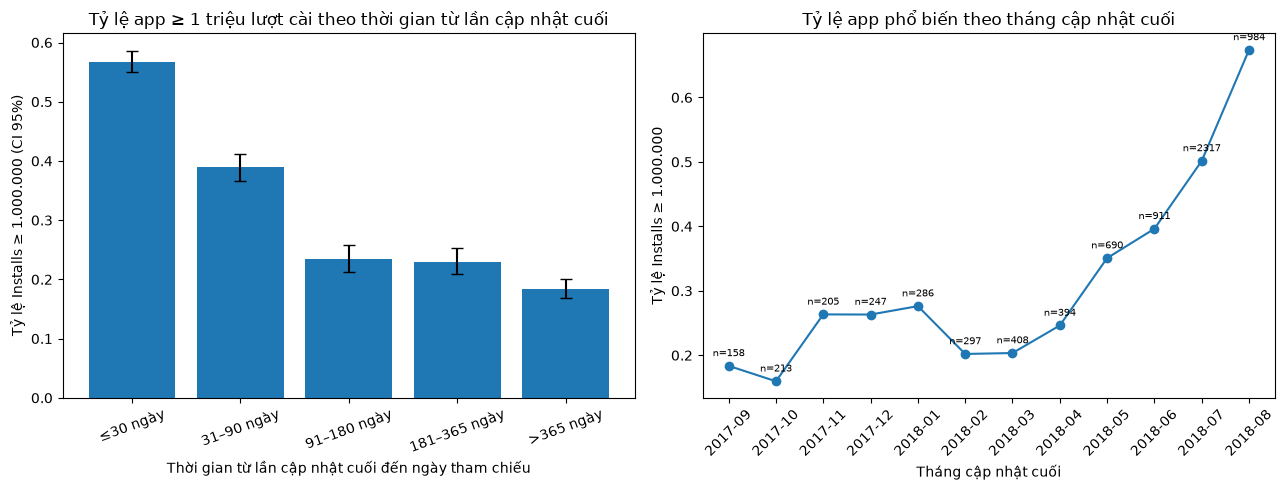

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: tỷ lệ phổ biến theo nhóm thời gian từ lần cập nhật cuối, CI bootstrap 95%
rng = np.random.default_rng(42)
shares, errs = [], []
for lab in AGE_LABELS:
    v = q2.loc[q2["Age_group"].eq(lab), "Popular"].to_numpy(float)
    m = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(1000)]
    lo, hi = np.percentile(m, [2.5, 97.5])
    shares.append(v.mean()); errs.append([v.mean() - lo, hi - v.mean()])
axes[0].bar(AGE_LABELS, shares, yerr=np.array(errs).T, capsize=4, color="C0")
axes[0].set(title="Tỷ lệ app ≥ 1 triệu lượt cài theo thời gian từ lần cập nhật cuối",
            xlabel="Thời gian từ lần cập nhật cuối đến ngày tham chiếu", ylabel="Tỷ lệ Installs ≥ 1.000.000 (CI 95%)")
axes[0].tick_params(axis="x", rotation=20)

# Biểu đồ 2: theo tháng cập nhật cuối (12 tháng gần nhất)
month = q2["Last Updated"].dt.to_period("M")
recent_months = month[month >= month.max() - 11].sort_values().unique()
cohort = q2[month.isin(recent_months)].groupby(month).agg(Popular_share=("Popular", "mean"), n=("App", "size"))
axes[1].plot(cohort.index.astype(str), cohort["Popular_share"], marker="o")
for x, (s, n) in enumerate(zip(cohort["Popular_share"], cohort["n"])):
    axes[1].annotate(f"n={n}", (x, s), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
axes[1].set(title="Tỷ lệ app phổ biến theo tháng cập nhật cuối", xlabel="Tháng cập nhật cuối", ylabel="Tỷ lệ Installs ≥ 1.000.000")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

- Biểu đồ trái: tỷ lệ phổ biến giảm dần qua bốn nhóm đầu (56,7%, 38,9%, 23,5%, 22,9%) rồi gần như phẳng ở nhóm >365 ngày (18,5%); các CI không chồng lấn ở ba bước đầu.
- Biểu đồ phải: tỷ lệ phổ biến tăng mạnh theo tháng cập nhật cuối, từ khoảng 16–28% trong 2017 và đầu 2018 lên 35,1% (tháng 5), 39,6% (tháng 6), 50,2% (tháng 7) và 67,4% (tháng 8/2018, 984 ứng dụng). Mối liên hệ không thay đổi mạnh ở các tháng cũ hơn, nên tác động tập trung ở nhóm cập nhật rất gần.

#### **4. Kiểm soát theo danh mục (D4)**

Nhóm lặp lại ước lượng bên trong từng danh mục có ít nhất 150 ứng dụng, với tầng là `Type`. Mỗi danh mục dùng bootstrap 500 lần.

,Category,n,Chênh sau phân tầng,CI,App dùng
0,MEDICAL,395,0.081,[0.047; 0.117],395
1,DATING,170,0.175,[0.046; 0.269],165
2,PRODUCTIVITY,374,0.221,[0.121; 0.317],346
3,PERSONALIZATION,376,0.222,[0.131; 0.307],376
4,FAMILY,1874,0.222,[0.183; 0.267],1874
5,BUSINESS,420,0.232,[0.155; 0.311],408
6,TOOLS,829,0.233,[0.170; 0.295],829
7,LIFESTYLE,369,0.270,[0.181; 0.354],350
8,GAME,946,0.285,[0.233; 0.342],946
9,PHOTOGRAPHY,281,0.295,[0.183; 0.410],262


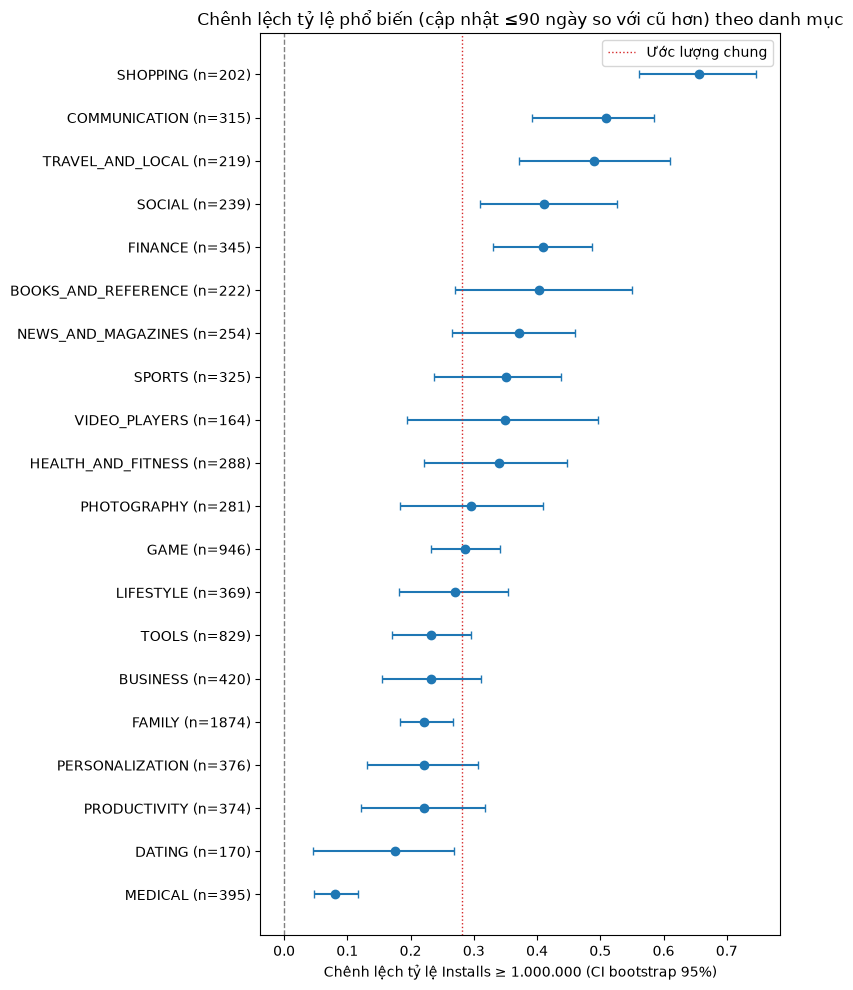

In [17]:
# D4: kiểm tra trong từng danh mục (tầng theo Type), chỉ giữ danh mục đủ lớn.
cat_rows = []
for cat, g in q2.groupby("Category"):
    if len(g) < 150:
        continue
    r = q2_estimate(g, strata=("Type",), n_boot=500)
    cat_rows.append({"Category": cat, "n": r["n"], "Chênh sau phân tầng": r["Chênh sau phân tầng"], "CI": r["CI phân tầng"], "App dùng": r["App dùng"]})
q2_cat = pd.DataFrame(cat_rows).sort_values("Chênh sau phân tầng").reset_index(drop=True)
q2_cat_view = q2_cat.assign(CI=q2_cat["CI"].map(lambda v: f"[{v[0]:.3f}; {v[1]:.3f}]")).round(3)
display(q2_cat_view)

err = np.array([[r["Chênh sau phân tầng"] - r["CI"][0], r["CI"][1] - r["Chênh sau phân tầng"]] for _, r in q2_cat.iterrows()]).T
fig, ax = plt.subplots(figsize=(8, 0.4 * len(q2_cat) + 2))
ax.errorbar(q2_cat["Chênh sau phân tầng"], range(len(q2_cat)), xerr=err, fmt="o", capsize=3)
ax.axvline(0, color="gray", ls="--", lw=1)
ax.axvline(q2_main["Chênh sau phân tầng"], color="C3", ls=":", lw=1, label="Ước lượng chung")
ax.set_yticks(range(len(q2_cat)), [f"{c} (n={n})" for c, n in zip(q2_cat["Category"], q2_cat["n"])])
ax.set(title="Chênh lệch tỷ lệ phổ biến (cập nhật ≤90 ngày so với cũ hơn) theo danh mục",
       xlabel="Chênh lệch tỷ lệ Installs ≥ 1.000.000 (CI bootstrap 95%)")
ax.legend()
plt.tight_layout()
plt.show()

- Chênh lệch dương ở cả 20 danh mục, và CI của mọi danh mục đều nằm hẳn phía dương. Mối liên hệ không phải do một vài danh mục tạo ra.
- Độ lớn khác nhau: thấp nhất ở `MEDICAL` (+0,081, CI [0,047; 0,117]) và `DATING` (+0,175); cao nhất ở `SHOPPING` (+0,656), `COMMUNICATION` (+0,508) và `TRAVEL_AND_LOCAL` (+0,490). `GAME` (+0,285) và `FAMILY` (+0,222) gần mức chung.
- Các danh mục nhỏ như `VIDEO_PLAYERS` hoặc `DATING` có CI rộng, nên nên đọc thận trọng.

#### **5. Kiểm tra độ bền (D6)**

Nhóm lặp lại phân tích khi đổi: ngưỡng "mới" (30, 90 hoặc 180 ngày), cách phân tầng (thêm `Size_group`), phạm vi mẫu (loại ứng dụng kích thước "Varies") và ngưỡng phổ biến (100.000, 1.000.000 hoặc 10.000.000).

In [18]:
# D6: đổi ngưỡng "mới", cách phân tầng, phạm vi mẫu và ngưỡng phổ biến.
variants = [
    ("Chính: ≤90 ngày, Category×Type", dict(d=q2)),
    ("Ngưỡng mới ≤30 ngày", dict(d=q2, cutoff=30)),
    ("Ngưỡng mới ≤180 ngày", dict(d=q2, cutoff=180)),
    ("Phân tầng thêm Size_group", dict(d=q2, strata=("Category", "Type", "Size_group"))),
    ("Loại app có Size 'Varies'", dict(d=q2[q2["Size_group"].ne("Varies")])),
    ("Phổ biến: Installs ≥ 100.000", dict(d=q2, thr=100_000)),
    ("Phổ biến: Installs ≥ 10.000.000", dict(d=q2, thr=10_000_000)),
]
rows = []
for label, kw in variants:
    r = q2_estimate(**kw)
    rows.append({"Biến thể": label, "n": r["n"], "App dùng": r["App dùng"], "Chênh thô": r["Chênh thô"],
                 "Chênh sau phân tầng": r["Chênh sau phân tầng"],
                 "CI 95%": f"[{r['CI phân tầng'][0]:.3f}; {r['CI phân tầng'][1]:.3f}]"})
q2_robust = pd.DataFrame(rows)
with pd.option_context("display.width", 200, "display.max_columns", None):
    display(q2_robust.round(3))

,Biến thể,n,App dùng,Chênh thô,Chênh sau phân tầng,CI 95%
0,"Chính: ≤90 ngày, Category×Type",9659,9412,0.291,0.281,[0.262; 0.297]
1,Ngưỡng mới ≤30 ngày,9659,9329,0.310,0.292,[0.273; 0.316]
2,Ngưỡng mới ≤180 ngày,9659,9433,0.247,0.244,[0.228; 0.262]
3,Phân tầng thêm Size_group,9659,7999,0.291,0.208,[0.182; 0.222]
4,Loại app có Size 'Varies',8431,8216,0.235,0.235,[0.215; 0.254]
5,Phổ biến: Installs ≥ 100.000,9659,9412,0.282,0.258,[0.240; 0.277]
6,Phổ biến: Installs ≥ 10.000.000,9659,9412,0.162,0.164,[0.150; 0.177]


- Chiều của kết quả không đổi ở cả 7 biến thể: chênh lệch sau phân tầng luôn dương và CI luôn nằm hẳn trên 0, từ **+0,164** đến **+0,292**.
- Độ lớn thay đổi theo lựa chọn. Thêm `Size_group` vào tầng làm chênh lệch giảm từ 0,281 xuống **0,208**, nghĩa là một phần mối liên hệ ban đầu đi cùng kích thước ứng dụng. Ngưỡng phổ biến cao hơn (≥10 triệu) cho chênh lệch nhỏ hơn (**+0,164**), vì ngưỡng khó đạt hơn nên tỷ lệ chung thấp hơn.
- Kết luận định tính (ứng dụng cập nhật gần đây phổ biến hơn) bền; con số cụ thể nhạy với ngưỡng và biến kiểm soát.

#### **6. Trả lời câu hỏi và giới hạn**

**Trả lời:** Có. Ứng dụng cập nhật trong 90 ngày gần nhất có tỷ lệ đạt từ 1 triệu lượt cài cao hơn **0,281** (CI 95% [0,262; 0,297]) so với ứng dụng cũ hơn, khi so sánh trong cùng danh mục và loại Free hoặc Paid (tỷ lệ thô 49,9% so với 20,8%). Mối liên hệ dương ở cả 20 danh mục lớn và ở cả 7 biến thể kiểm tra, dao động từ 0,164 đến 0,292; khi kiểm soát thêm kích thước, ước lượng còn 0,208. Spearman giữa số ngày từ lần cập nhật cuối và `Installs` là −0,332. Với nhà phát triển, duy trì cập nhật đi cùng khả năng đạt quy mô lớn, nhưng chưa chứng minh được cập nhật gây ra điều đó.

**Giới hạn:**
- Đây là mối liên hệ quan sát, và có thể đảo chiều: ứng dụng đông người dùng có nhiều nguồn lực để cập nhật thường xuyên hơn.
- `Last Updated` chỉ là ngày cập nhật cuối, không cho biết tần suất cập nhật. Ngày tham chiếu 08/08/2018 là xấp xỉ ngày thu thập, nên "độ mới" phụ thuộc thời điểm cào dữ liệu.
- `Installs` là cận dưới theo ngưỡng, và dữ liệu không có ứng dụng đã bị gỡ khỏi cửa hàng (thiên lệch sống sót).
- Một số danh mục chỉ có 150–400 ứng dụng, nên CI theo danh mục khá rộng; ngưỡng "mới ≤90 ngày" là lựa chọn của nhóm.